In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from torchvision import datasets
from torchvision.transforms import ToTensor

In [2]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

100%|█████████████████████████████████████████████████████████████████████████████| 26.4M/26.4M [00:12<00:00, 2.16MB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 29.5k/29.5k [00:00<00:00, 9.82MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 4.42M/4.42M [00:06<00:00, 723kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 5.15k/5.15k [00:00<00:00, 5.14MB/s]


In [3]:
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 60000
Testing samples: 10000


Image shape: torch.Size([1, 28, 28])
Label: 9
Class name: Ankle boot


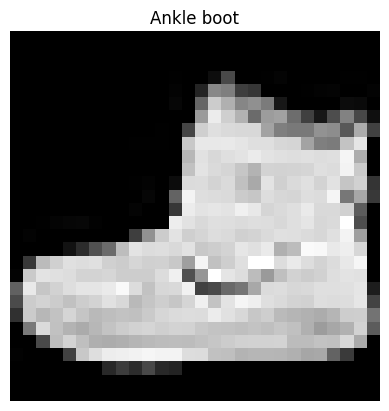

In [4]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
image, label = train_data[0]
print("Image shape:", image.shape)
print("Label:", label)
print("Class name:", class_names[label])
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis("off")
plt.show()

In [5]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32
train_dataloader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_dataloader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)
print("Training batches:", len(train_dataloader))
print("Testing batches:", len(test_dataloader))

Training batches: 1875
Testing batches: 313


In [6]:
class FashionMNISTModelV0(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layer_stack = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, output_features)
        )
    def forward(self, x):
        x = self.flatten(x)
        return self.layer_stack(x)
model_0 = FashionMNISTModelV0(
    input_features=784,
    output_features=10,
    hidden_units=10
)
print(model_0)

FashionMNISTModelV0(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layer_stack): Sequential(
    (0): Linear(in_features=784, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)


In [7]:
sample_images, sample_labels = next(iter(train_dataloader))
predictions = model_0(sample_images)
print("Input batch shape:", sample_images.shape)
print("Output shape:", predictions.shape)
print("First image logits:", predictions[0])

Input batch shape: torch.Size([32, 1, 28, 28])
Output shape: torch.Size([32, 10])
First image logits: tensor([ 0.0326, -0.4985,  0.3270,  0.0193,  0.2373,  0.1507, -0.0228, -0.0822,
        -0.0942,  0.0639], grad_fn=<SelectBackward0>)


In [8]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    params=model_0.parameters(),
    lr=0.1
)
print("Loss function:", loss_fn)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [9]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    accuracy = (correct / len(y_true)) * 100
    return accuracy

In [10]:
from timeit import default_timer as timer
start_time = timer()
epochs = 3
for epoch in range(epochs):
    print(f"\nEpoch: {epoch + 1}/{epochs}")
    train_loss = 0
    model_0.train()
    for batch, (X, y) in enumerate(train_dataloader):
        y_pred = model_0(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if batch % 500 == 0:
            print(f"Batch: {batch}/{len(train_dataloader)}")
    train_loss /= len(train_dataloader)
    print(f"Average training loss: {train_loss:.4f}")
end_time = timer()
print(f"\nTraining time: {end_time - start_time:.2f} seconds")


Epoch: 1/3
Batch: 0/1875
Batch: 500/1875
Batch: 1000/1875
Batch: 1500/1875
Average training loss: 0.6533

Epoch: 2/3
Batch: 0/1875
Batch: 500/1875
Batch: 1000/1875
Batch: 1500/1875
Average training loss: 0.4933

Epoch: 3/3
Batch: 0/1875
Batch: 500/1875
Batch: 1000/1875
Batch: 1500/1875
Average training loss: 0.4571

Training time: 58.03 seconds


In [11]:
model_0.eval()
test_loss = 0
test_accuracy = 0
with torch.inference_mode():
    for X, y in test_dataloader:
        test_pred = model_0(X)
        loss = loss_fn(test_pred, y)
        test_loss += loss.item()
        predicted_classes = torch.argmax(test_pred, dim=1)
        test_accuracy += accuracy_fn(
            y_true=y,
            y_pred=predicted_classes
        )
test_loss /= len(test_dataloader)
test_accuracy /= len(test_dataloader)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2f}%")

Test loss: 0.4727
Test accuracy: 83.52%


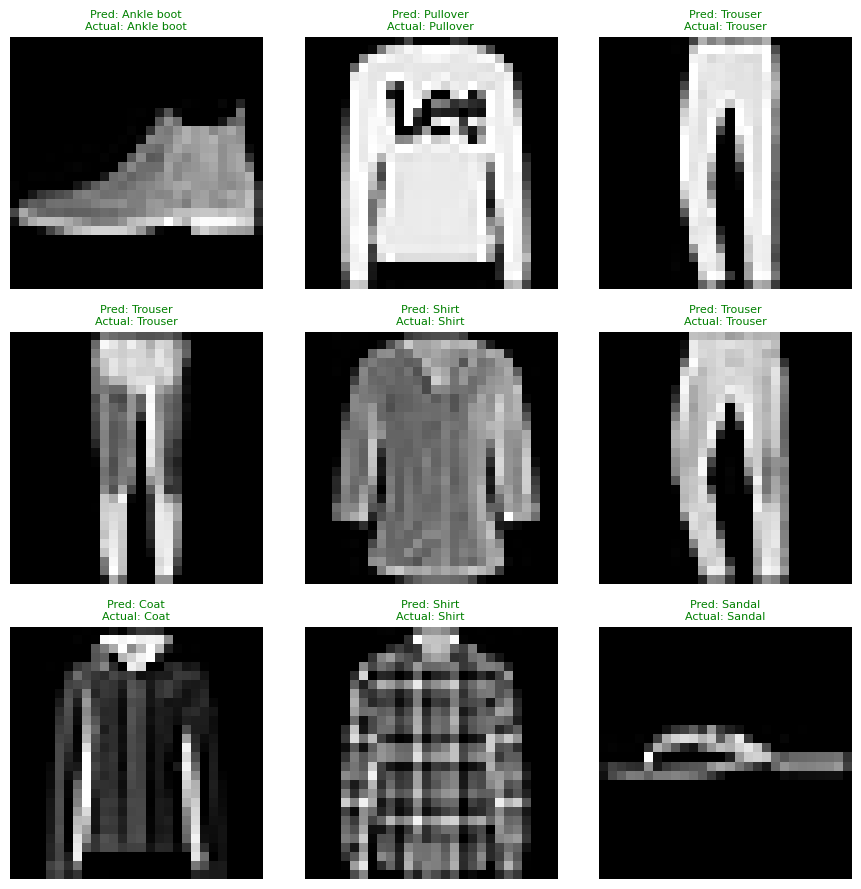

In [12]:
images, labels = next(iter(test_dataloader))
model_0.eval()
with torch.inference_mode():
    logits = model_0(images)
predictions = torch.argmax(logits, dim=1)
plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    predicted_label = class_names[predictions[i].item()]
    actual_label = class_names[labels[i].item()]
    color = "green" if predictions[i] == labels[i] else "red"
    plt.title(
        f"Pred: {predicted_label}\nActual: {actual_label}",
        color=color,
        fontsize=8
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "fashion_mnist_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
torch.save(model_0.state_dict(), MODEL_SAVE_PATH)
print(f"Model saved to: {MODEL_SAVE_PATH}")

Model saved to: models\fashion_mnist_model_0.pth


In [14]:
loaded_model = FashionMNISTModelV0(
    input_features=784,
    output_features=10,
    hidden_units=10
)
loaded_model.load_state_dict(
    torch.load(MODEL_SAVE_PATH, map_location="cpu", weights_only=True)
)
loaded_model.eval()
with torch.inference_mode():
    loaded_logits = loaded_model(images)
loaded_predictions = torch.argmax(loaded_logits, dim=1)
print("Original predictions:", predictions[:10])
print("Loaded model predictions:", loaded_predictions[:10])
print(
    "Predictions match:",
    torch.equal(predictions, loaded_predictions)
)

Original predictions: tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])
Loaded model predictions: tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])
Predictions match: True


In [15]:
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_channels, hidden_units, output_features):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input_channels,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(hidden_units * 7 * 7, output_features)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.classifier(x)
        return x

In [16]:
torch.manual_seed(42)

model_1 = FashionMNISTModelV1(
    input_channels=1,
    hidden_units=10,
    output_features=10
)

print(model_1)

FashionMNISTModelV1(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)


In [17]:
sample_images, sample_labels = next(iter(train_dataloader))

model_1.eval()

with torch.inference_mode():
    cnn_predictions = model_1(sample_images)

print("Input shape:", sample_images.shape)
print("CNN output shape:", cnn_predictions.shape)

Input shape: torch.Size([32, 1, 28, 28])
CNN output shape: torch.Size([32, 10])


In [18]:
loss_fn_cnn = nn.CrossEntropyLoss()

optimizer_cnn = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.1
)

epochs = 3

for epoch in range(epochs):
    model_1.train()
    train_loss = 0.0

    for X, y in train_dataloader:
        y_pred = model_1(X)

        loss = loss_fn_cnn(y_pred, y)
        train_loss += loss.item()

        optimizer_cnn.zero_grad()
        loss.backward()
        optimizer_cnn.step()

    train_loss /= len(train_dataloader)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Training loss: {train_loss:.4f}"
    )

Epoch 1/3 | Training loss: 0.6017
Epoch 2/3 | Training loss: 0.3677
Epoch 3/3 | Training loss: 0.3344


In [19]:
model_1.eval()

cnn_test_loss = 0.0
cnn_test_accuracy = 0.0

with torch.inference_mode():
    for X, y in test_dataloader:
        test_logits = model_1(X)

        loss = loss_fn_cnn(test_logits, y)
        cnn_test_loss += loss.item()

        test_predictions = torch.argmax(test_logits, dim=1)

        cnn_test_accuracy += accuracy_fn(
            y_true=y,
            y_pred=test_predictions
        )

cnn_test_loss /= len(test_dataloader)
cnn_test_accuracy /= len(test_dataloader)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.2f}%")

CNN test loss: 0.3869
CNN test accuracy: 85.84%


In [20]:
def evaluate_model(model, dataloader, loss_fn):
    model.eval()

    total_loss = 0.0
    total_accuracy = 0.0

    with torch.inference_mode():
        for X, y in dataloader:
            logits = model(X)

            loss = loss_fn(logits, y)
            total_loss += loss.item()

            predictions = torch.argmax(logits, dim=1)

            total_accuracy += accuracy_fn(
                y_true=y,
                y_pred=predictions
            )

    total_loss /= len(dataloader)
    total_accuracy /= len(dataloader)

    return {
        "loss": total_loss,
        "accuracy": total_accuracy
    }


model_0_results = evaluate_model(
    model_0, test_dataloader, loss_fn
)

model_1_results = evaluate_model(
    model_1, test_dataloader, loss_fn_cnn
)

print("Fully connected model:", model_0_results)
print("CNN model:", model_1_results)

Fully connected model: {'loss': 0.4726986436131663, 'accuracy': 83.51637380191693}
CNN model: {'loss': 0.3869018192275073, 'accuracy': 85.84265175718849}


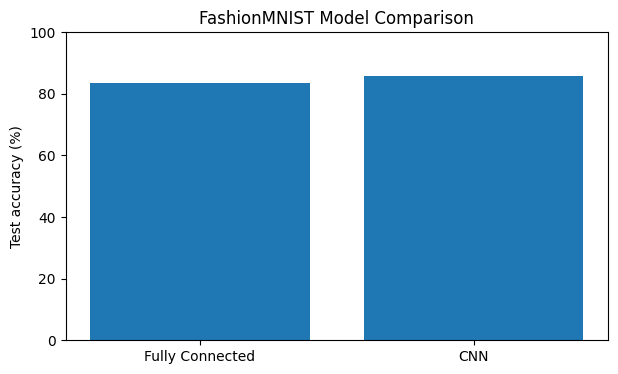

In [21]:
models = ["Fully Connected", "CNN"]

accuracies = [
    model_0_results["accuracy"],
    model_1_results["accuracy"]
]

plt.figure(figsize=(7, 4))
plt.bar(models, accuracies)
plt.ylabel("Test accuracy (%)")
plt.title("FashionMNIST Model Comparison")
plt.ylim(0, 100)
plt.show()

In [22]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

CNN_SAVE_PATH = MODEL_PATH / "fashion_mnist_cnn.pth"

torch.save(model_1.state_dict(), CNN_SAVE_PATH)

print("CNN saved to:", CNN_SAVE_PATH)

CNN saved to: models\fashion_mnist_cnn.pth


In [23]:
loaded_cnn = FashionMNISTModelV1(
    input_channels=1,
    hidden_units=10,
    output_features=10
)

loaded_cnn.load_state_dict(
    torch.load(
        CNN_SAVE_PATH,
        map_location="cpu",
        weights_only=True
    )
)

loaded_cnn.eval()

# Test the restored model
images, labels = next(iter(test_dataloader))

with torch.inference_mode():
    original_logits = model_1(images)
    loaded_logits = loaded_cnn(images)

print(
    "Predictions match:",
    torch.equal(
        torch.argmax(original_logits, dim=1),
        torch.argmax(loaded_logits, dim=1)
    )
)

Predictions match: True


In [24]:
image, label = train_data[0]

# A convolution layer with one input and one output channel
conv_layer = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=1
)

# Pooling reduces the image dimensions
pool_layer = nn.MaxPool2d(kernel_size=2)

# Add batch dimension: [1, 28, 28] -> [1, 1, 28, 28]
image_batch = image.unsqueeze(0)

with torch.inference_mode():
    convolved_image = conv_layer(image_batch)
    pooled_image = pool_layer(convolved_image)

print("Original:", image_batch.shape)
print("After convolution:", convolved_image.shape)
print("After pooling:", pooled_image.shape)

Original: torch.Size([1, 1, 28, 28])
After convolution: torch.Size([1, 1, 28, 28])
After pooling: torch.Size([1, 1, 14, 14])


In [25]:
model_1.eval()

all_predictions = []
all_labels = []

with torch.inference_mode():
    for X, y in test_dataloader:
        logits = model_1(X)
        predictions = torch.argmax(logits, dim=1)

        all_predictions.append(predictions)
        all_labels.append(y)

# Combine all batches into one tensor
all_predictions = torch.cat(all_predictions)
all_labels = torch.cat(all_labels)

print("Predictions shape:", all_predictions.shape)
print("Labels shape:", all_labels.shape)

Predictions shape: torch.Size([10000])
Labels shape: torch.Size([10000])


In [27]:
from torchmetrics import ConfusionMatrix

confmat = ConfusionMatrix(
    task="multiclass",
    num_classes=len(class_names)
)

matrix = confmat(
    all_predictions,
    all_labels
)

print(matrix)

tensor([[925,   0,  22,   7,   4,   2,  33,   0,   7,   0],
        [ 10, 966,   5,   9,   2,   0,   6,   0,   2,   0],
        [ 20,   2, 899,   4,  34,   0,  38,   0,   3,   0],
        [ 89,   3,  29, 831,  26,   0,  16,   0,   6,   0],
        [  6,   1, 224,  31, 625,   0, 109,   0,   4,   0],
        [  0,   0,   2,   1,   0, 980,   0,   9,   2,   6],
        [282,   2, 141,  13,  47,   0, 501,   0,  12,   2],
        [  0,   0,   0,   0,   0,  44,   0, 909,   0,  47],
        [  4,   1,   6,   3,   1,   3,   3,   2, 977,   0],
        [  0,   0,   0,   0,   0,   7,   0,  23,   0, 970]])


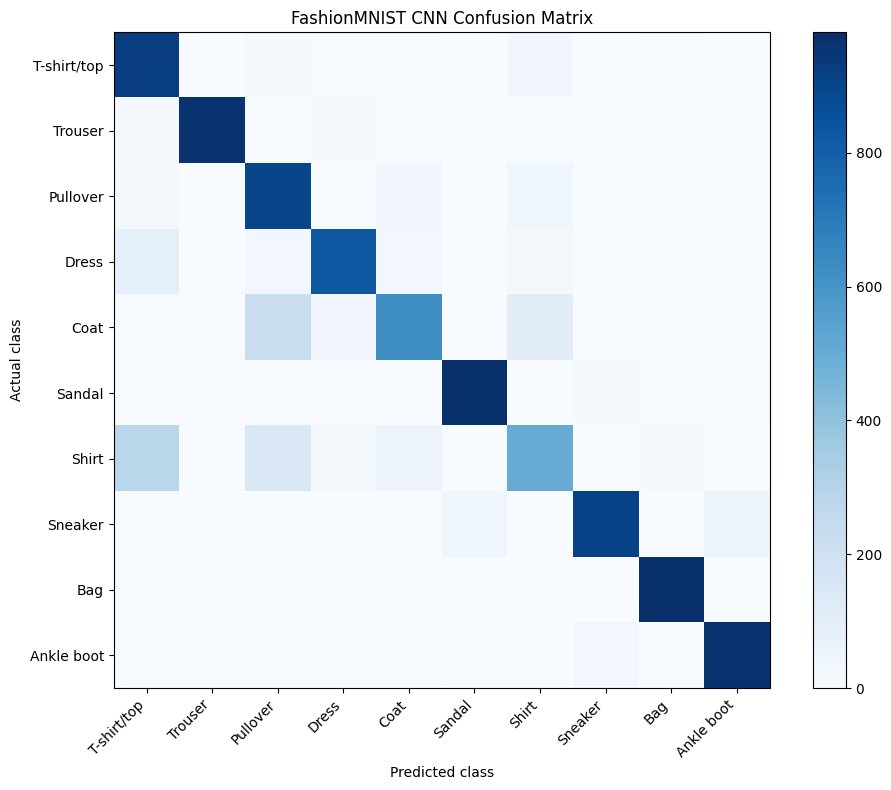

In [28]:
plt.figure(figsize=(10, 8))

plt.imshow(matrix.numpy(), cmap="Blues")
plt.title("FashionMNIST CNN Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

plt.colorbar()
plt.tight_layout()
plt.show()

In [29]:
# Copy the matrix and remove correct predictions
errors = matrix.clone()
errors.fill_diagonal_(0)

# Find the largest off-diagonal entry
max_error_index = torch.argmax(errors)
actual_class = max_error_index // len(class_names)
predicted_class = max_error_index % len(class_names)

print("Most confused actual class:", class_names[actual_class.item()])
print("Most confused predicted class:", class_names[predicted_class.item()])
print("Number of mistakes:", errors.max().item())

Most confused actual class: Shirt
Most confused predicted class: T-shirt/top
Number of mistakes: 282
